# Multimodal Movie Genre Classification

This notebook investigates multi-label movie genre prediction using the MM-IMDb dataset. Each movie may belong to several of 23 genres.

Four approaches are compared:

1. Text-only model
2. Poster-only model
3. Early fusion of text and poster features
4. Late fusion of text and poster predictions

The models are evaluated using micro-F1, macro-F1, mean per-genre average precision, exact-match accuracy and Hamming loss.

## 1. Setup and Reproducibility

This section imports the required libraries, selects the available computing device and sets random seeds to make the experiment more reproducible. Results may still vary slightly across hardware and training runs.

In [3]:
# Standard-library imports
import copy
import json
import random
from pathlib import Path

# Data handling and visualisation
import h5py
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Machine learning
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    hamming_loss,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Select the available computing device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Random seed:", SEED)
print("Using device:", device)

/opt/anaconda3/envs/audio_assignment/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Random seed: 42
Using device: mps


In [4]:


# Download the dataset and turn the returned path into a Path object
path = Path(kagglehub.dataset_download("johnarevalo/mmimdb"))

print("Dataset downloaded to:", path)


# Download the MM-IMDb dataset from Kaggle
path = Path(kagglehub.dataset_download("johnarevalo/mmimdb"))

print("Dataset downloaded to:", path)


Dataset downloaded to: /Users/abhisheksharma/.cache/kagglehub/datasets/johnarevalo/mmimdb/versions/1
Dataset downloaded to: /Users/abhisheksharma/.cache/kagglehub/datasets/johnarevalo/mmimdb/versions/1


## 2. Dataset Loading

The MM-IMDb dataset is downloaded from Kaggle. The HDF5 file contains pre-extracted text features, VGG poster features and multi-label genre targets.

The original dataset split is retained:

- 15,552 training movies
- 2,608 validation movies
- 7,799 test movies

In [6]:


h5_path = path / "multimodal_imdb.hdf5"
with h5py.File(h5_path, "r") as f:
    print("Top-level items:", list(f.keys()))

    def show_item(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name} | shape={obj.shape} | dtype={obj.dtype}")
        else:
            print(f"{name}/")

    f.visititems(show_item)

Top-level items: ['features', 'genres', 'images', 'imdb_ids', 'sequences', 'three_grams', 'vgg_features', 'word_grams']
features | shape=(25959, 300) | dtype=float32
genres | shape=(25959, 23) | dtype=int32
images | shape=(25959, 3, 256, 160) | dtype=int32
imdb_ids | shape=(25959,) | dtype=|S7
sequences | shape=(25959,) | dtype=object
three_grams | shape=(25959, 9946) | dtype=float32
vgg_features | shape=(25959, 4096) | dtype=float32
word_grams | shape=(25959, 13253) | dtype=float32


In [7]:
with h5py.File(h5_path, "r") as f:
    print("File attributes:")
    for name, value in f.attrs.items():
        print(f"{name}: {value}")

    print("\nRelevant dataset attributes:")
    for name in ["genres", "features", "vgg_features"]:
        dataset = f[name]
        print(f"\n{name}:")
        for attr_name, attr_value in dataset.attrs.items():
            print(f"  {attr_name}: {attr_value}")

File attributes:
split: [(b'train', b'features',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'genres',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'images',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'imdb_ids',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'sequences',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'three_grams',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'vgg_features',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'train', b'word_grams',     0, 15552, <HDF5 object reference (null)>,  True, b'.')
 (b'dev', b'features', 15552, 18160, <HDF5 object reference (null)>,  True, b'.')
 (b'dev', b'genres', 15552, 18160, <HDF5 object reference (null)>,  True, b'.')
 (b'dev', b'images', 15552, 18160, <HDF5 object reference (null)>,  True, b'.')
 (b'dev', b'imdb_ids', 15552, 18160, <HDF5 object refere

In [8]:


# The split boundaries shown in the HDF5 file
TRAIN_END = 15552
DEV_END = 18160  # train + validation

with h5py.File(h5_path, "r") as f:
    # Read the genre names in the same order as the columns in "genres"
    raw_names = f["genres"].attrs["target_names"]
    if isinstance(raw_names, bytes):
        raw_names = raw_names.decode("utf-8")
    genre_names = json.loads(raw_names)

    # Text features: 300 values per movie
    X_text_train = f["features"][:TRAIN_END].astype(np.float32)
    X_text_val = f["features"][TRAIN_END:DEV_END].astype(np.float32)
    X_text_test = f["features"][DEV_END:].astype(np.float32)

    # Poster features: 4096 values per movie
    X_image_train = f["vgg_features"][:TRAIN_END].astype(np.float32)
    X_image_val = f["vgg_features"][TRAIN_END:DEV_END].astype(np.float32)
    X_image_test = f["vgg_features"][DEV_END:].astype(np.float32)

    # Multi-label targets: 23 binary genre values per movie
    y_train = f["genres"][:TRAIN_END].astype(np.float32)
    y_val = f["genres"][TRAIN_END:DEV_END].astype(np.float32)
    y_test = f["genres"][DEV_END:].astype(np.float32)

print("Genres:", genre_names)
print("\nShapes:")
print("Text:", X_text_train.shape, X_text_val.shape, X_text_test.shape)
print("Poster:", X_image_train.shape, X_image_val.shape, X_image_test.shape)
print("Labels:", y_train.shape, y_val.shape, y_test.shape)

print("\nTraining examples per genre:")
for name, count in zip(genre_names, y_train.sum(axis=0).astype(int)):
    print(f"{name}: {count}")

Genres: ['Drama', 'Comedy', 'Romance', 'Thriller', 'Crime', 'Action', 'Adventure', 'Horror', 'Documentary', 'Mystery', 'Sci-Fi', 'Fantasy', 'Family', 'Biography', 'War', 'History', 'Music', 'Animation', 'Musical', 'Western', 'Sport', 'Short', 'Film-Noir']

Shapes:
Text: (15552, 300) (2608, 300) (7799, 300)
Poster: (15552, 4096) (2608, 4096) (7799, 4096)
Labels: (15552, 23) (2608, 23) (7799, 23)

Training examples per genre:
Drama: 8424
Comedy: 5108
Romance: 3226
Thriller: 3113
Crime: 2293
Action: 2155
Adventure: 1611
Horror: 1603
Documentary: 1234
Mystery: 1231
Sci-Fi: 1212
Fantasy: 1162
Family: 978
Biography: 788
War: 806
History: 680
Music: 634
Animation: 586
Musical: 503
Western: 423
Sport: 379
Short: 281
Film-Noir: 202


## 3. Data-Quality Assessment

The dataset is checked for invalid values, inconsistent dimensions and label-format problems. Genre frequencies are also examined to identify class imbalance.

Each movie has between 1 and 10 genres, with an average of approximately 2.48 genres. Common genres such as Drama have considerably more examples than rare genres such as Short and Film-Noir.

In [10]:


# Check that each genre label is either 0 (absent) or 1 (present)
print("Unique training label values:", np.unique(y_train))
print("Average genres per training movie:", y_train.sum(axis=1).mean())
print("Minimum genres per movie:", int(y_train.sum(axis=1).min()))
print("Maximum genres per movie:", int(y_train.sum(axis=1).max()))

# Check that feature arrays contain only finite numbers
feature_arrays = {
    "Text train": X_text_train,
    "Poster train": X_image_train,
    "Text validation": X_text_val,
    "Poster validation": X_image_val,
    "Text test": X_text_test,
    "Poster test": X_image_test,
}

for name, array in feature_arrays.items():
    print(
        f"{name}: all finite = {np.isfinite(array).all()}, "
        f"shape = {array.shape}"
    )

# Compare the number of positive examples for every genre across splits
genre_summary = pd.DataFrame({
    "Genre": genre_names,
    "Train positives": y_train.sum(axis=0).astype(int),
    "Validation positives": y_val.sum(axis=0).astype(int),
    "Test positives": y_test.sum(axis=0).astype(int),
})

display(genre_summary)

Unique training label values: [0. 1.]
Average genres per training movie: 2.4840536
Minimum genres per movie: 1
Maximum genres per movie: 10
Text train: all finite = True, shape = (15552, 300)
Poster train: all finite = True, shape = (15552, 4096)
Text validation: all finite = True, shape = (2608, 300)
Poster validation: all finite = True, shape = (2608, 4096)
Text test: all finite = True, shape = (7799, 300)
Poster test: all finite = True, shape = (7799, 4096)


,Genre,Train positives,Validation positives,Test positives
0,Drama,8424,1401,4142
1,Comedy,5108,873,2611
2,Romance,3226,548,1590
3,Thriller,3113,512,1567
4,Crime,2293,382,1163
5,Action,2155,351,1044
6,Adventure,1611,278,821
7,Horror,1603,275,825
8,Documentary,1234,219,629
9,Mystery,1231,209,617


## 4. Preprocessing

Text and poster features are standardised separately. Each scaler is fitted only on the training data and then applied to the validation and test sets. This prevents information from the validation or test data leaking into model training.

In [12]:

# Create a separate scaler for each modality
text_scaler = StandardScaler()
poster_scaler = StandardScaler()

# Learn scaling values from training data, then apply them to all splits
X_text_train_scaled = text_scaler.fit_transform(X_text_train)
X_text_val_scaled = text_scaler.transform(X_text_val)
X_text_test_scaled = text_scaler.transform(X_text_test)

X_image_train_scaled = poster_scaler.fit_transform(X_image_train)
X_image_val_scaled = poster_scaler.transform(X_image_val)
X_image_test_scaled = poster_scaler.transform(X_image_test)

print("Scaled text shapes:",
      X_text_train_scaled.shape,
      X_text_val_scaled.shape,
      X_text_test_scaled.shape)

print("Scaled poster shapes:",
      X_image_train_scaled.shape,
      X_image_val_scaled.shape,
      X_image_test_scaled.shape)

Scaled text shapes: (15552, 300) (2608, 300) (7799, 300)
Scaled poster shapes: (15552, 4096) (2608, 4096) (7799, 4096)


## 5. Model Architecture

All unimodal and fusion approaches use a feed-forward neural network with:

- A 256-unit hidden layer with ReLU activation
- Dropout of 0.3
- A 128-unit hidden layer with ReLU activation
- Dropout of 0.2
- A 23-unit output layer containing one logit for each genre

Binary cross-entropy with logits is used because every genre is treated as a separate binary prediction.

In [14]:
from pathlib import Path
print(Path.cwd())

/Users/abhisheksharma/Desktop/mmimdb-multimodal-genre-classification


In [15]:





# A feed-forward neural network with one output for each of the 23 genres
class GenreMLP(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, output_size)
        )

    def forward(self, x):
        return self.network(x)



## 6. Model Training

The text-only, poster-only and early-fusion models are trained using Adam, mini-batches of 128 movies and a maximum of 30 epochs.

Validation loss is calculated after every epoch. Early stopping with a patience of five epochs is used, and the weights from the epoch with the lowest validation loss are restored.

Epoch 01 | train loss: 0.2896 | validation loss: 0.2161
Epoch 05 | train loss: 0.1910 | validation loss: 0.1940
Epoch 10 | train loss: 0.1796 | validation loss: 0.1917
Epoch 15 | train loss: 0.1715 | validation loss: 0.1919
Early stopping at epoch 15

Best validation loss: 0.1917


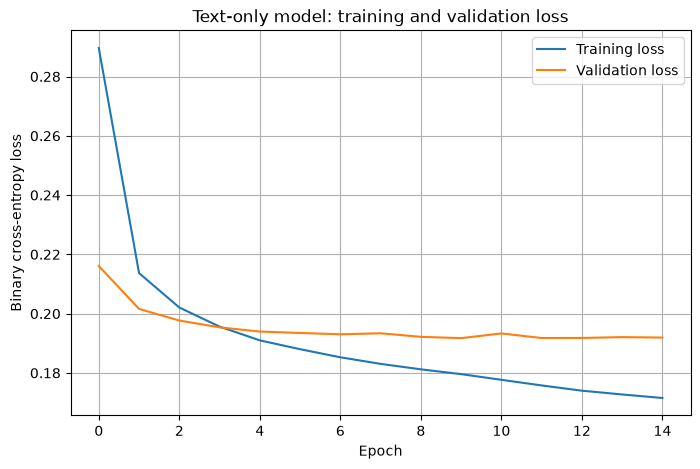

In [17]:

# Convert NumPy arrays into PyTorch tensors
X_train_tensor = torch.tensor(X_text_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_text_val_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

# Mini-batches let the model update using a small group of movies at a time
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

# Create the model
text_model = GenreMLP(
    input_size=X_text_train_scaled.shape[1],
    output_size=y_train.shape[1]
).to(device)

# Multi-label loss: each genre is treated as its own yes/no prediction
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    text_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# Train and monitor validation loss for overfitting
train_losses = []
val_losses = []
best_val_loss = float("inf")
best_state = None
patience = 5
epochs_without_improvement = 0
max_epochs = 30

for epoch in range(max_epochs):
    # Training pass
    text_model.train()
    train_loss_total = 0.0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        logits = text_model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * batch_x.size(0)

    average_train_loss = train_loss_total / len(train_dataset)
    train_losses.append(average_train_loss)

    # Validation pass: measure performance without updating the model
    text_model.eval()
    with torch.no_grad():
        val_logits = text_model(X_val_tensor.to(device))
        val_loss = criterion(val_logits, y_val_tensor.to(device)).item()

    val_losses.append(val_loss)

    # Keep the model state with the lowest validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(text_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:02d} | "
            f"train loss: {average_train_loss:.4f} | "
            f"validation loss: {val_loss:.4f}"
        )

    # Stop if validation loss has not improved for five epochs
    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# Restore the best version according to validation loss
text_model.load_state_dict(best_state)

print(f"\nBest validation loss: {best_val_loss:.4f}")

# Plot learning curves to check for overfitting
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Text-only model: training and validation loss")
plt.legend()
plt.grid(True)
plt.show()

In [18]:


# Get predicted probabilities for each genre on the validation set
text_model.eval()

with torch.no_grad():
    val_logits = text_model(X_val_tensor.to(device))
    text_val_probs = torch.sigmoid(val_logits).cpu().numpy()

# Turn probabilities into yes/no predictions using 0.5 as the cutoff
text_val_preds = (text_val_probs >= 0.5).astype(int)
y_val_int = y_val.astype(int)

# Overall F1 scores
micro_f1 = f1_score(
    y_val_int, text_val_preds, average="micro", zero_division=0
)
macro_f1 = f1_score(
    y_val_int, text_val_preds, average="macro", zero_division=0
)

# Precision, recall, and F1 for each genre
precision, recall, genre_f1, support = precision_recall_fscore_support(
    y_val_int,
    text_val_preds,
    average=None,
    zero_division=0
)

# Average Precision for each genre
genre_ap = average_precision_score(
    y_val_int,
    text_val_probs,
    average=None
)

print(f"Validation micro-F1 at 0.5 cutoff: {micro_f1:.4f}")
print(f"Validation macro-F1 at 0.5 cutoff: {macro_f1:.4f}")
print(f"Mean per-genre AP: {genre_ap.mean():.4f}")

text_results = pd.DataFrame({
    "Genre": genre_names,
    "Precision": precision,
    "Recall": recall,
    "F1": genre_f1,
    "Average Precision": genre_ap,
    "Positive examples": support
})

display(text_results.sort_values("Average Precision"))

Validation micro-F1 at 0.5 cutoff: 0.5848
Validation macro-F1 at 0.5 cutoff: 0.4563
Mean per-genre AP: 0.5410


,Genre,Precision,Recall,F1,Average Precision,Positive examples
22,Film-Noir,0.000000,0.000000,0.000000,0.098300,34
21,Short,0.625000,0.104167,0.178571,0.193512,48
18,Musical,0.400000,0.023529,0.044444,0.208909,85
17,Animation,0.578947,0.209524,0.307692,0.358098,105
15,History,0.666667,0.118644,0.201439,0.410747,118
13,Biography,0.604167,0.201389,0.302083,0.425965,144
9,Mystery,0.568966,0.157895,0.247191,0.432626,209
6,Adventure,0.631579,0.345324,0.446512,0.500303,278
12,Family,0.698795,0.337209,0.454902,0.511302,172
11,Fantasy,0.645833,0.333333,0.439716,0.519075,186


## 7. Threshold Optimisation

The models initially produce probabilities between 0 and 1. These probabilities must be converted into binary genre predictions.

For each model and genre, thresholds from 0.05 to 0.95 are evaluated on the validation set. The threshold producing the highest validation F1 score is selected and later applied unchanged to the test set.

In [20]:

# Try candidate probability cutoffs for each genre
threshold_grid = np.arange(0.05, 0.96, 0.05)
text_thresholds = []

for genre_index in range(y_val.shape[1]):
    best_threshold = 0.5
    best_f1 = -1

    for threshold in threshold_grid:
        predictions = (
            text_val_probs[:, genre_index] >= threshold
        ).astype(int)

        score = f1_score(
            y_val_int[:, genre_index],
            predictions,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    text_thresholds.append(best_threshold)

text_thresholds = np.array(text_thresholds)

# Apply each genre's selected cutoff to its validation probabilities
text_val_preds_tuned = (
    text_val_probs >= text_thresholds.reshape(1, -1)
).astype(int)

tuned_micro_f1 = f1_score(
    y_val_int, text_val_preds_tuned, average="micro", zero_division=0
)
tuned_macro_f1 = f1_score(
    y_val_int, text_val_preds_tuned, average="macro", zero_division=0
)

precision, recall, tuned_f1, support = precision_recall_fscore_support(
    y_val_int,
    text_val_preds_tuned,
    average=None,
    zero_division=0
)

print(f"Tuned validation micro-F1: {tuned_micro_f1:.4f}")
print(f"Tuned validation macro-F1: {tuned_macro_f1:.4f}")

tuned_text_results = pd.DataFrame({
    "Genre": genre_names,
    "Cutoff": text_thresholds,
    "Precision": precision,
    "Recall": recall,
    "F1": tuned_f1,
    "Average Precision": genre_ap,
    "Positive examples": support
})

display(tuned_text_results.sort_values("F1"))

Tuned validation micro-F1: 0.6169
Tuned validation macro-F1: 0.5441


,Genre,Cutoff,Precision,Recall,F1,Average Precision,Positive examples
22,Film-Noir,0.10,0.128000,0.470588,0.201258,0.098300,34
21,Short,0.35,0.571429,0.166667,0.258065,0.193512,48
18,Musical,0.10,0.207254,0.470588,0.287770,0.208909,85
17,Animation,0.20,0.326923,0.485714,0.390805,0.358098,105
15,History,0.20,0.392638,0.542373,0.455516,0.410747,118
9,Mystery,0.20,0.396491,0.540670,0.457490,0.432626,209
13,Biography,0.25,0.432927,0.493056,0.461039,0.425965,144
12,Family,0.25,0.441748,0.529070,0.481481,0.511302,172
6,Adventure,0.35,0.527132,0.489209,0.507463,0.500303,278
11,Fantasy,0.25,0.433692,0.650538,0.520430,0.519075,186


Poster-only | Epoch 01 | train loss: 0.2942 | validation loss: 0.2533
Poster-only | Epoch 05 | train loss: 0.2220 | validation loss: 0.2564
Poster-only: early stopping at epoch 8
Poster-only: best epoch = 3
Poster-only: best validation loss = 0.2512


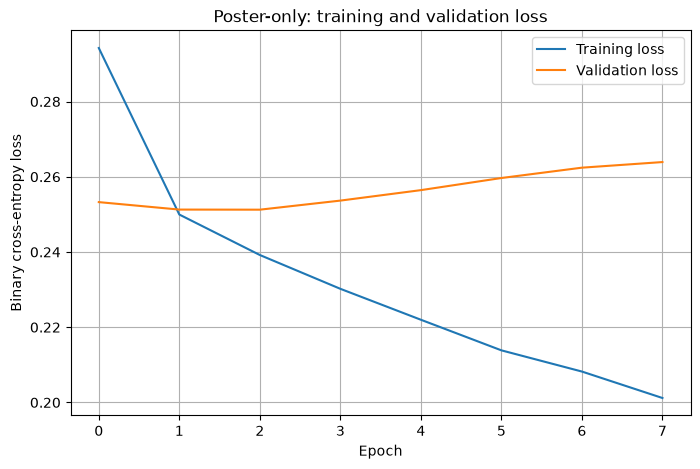

In [21]:


def train_genre_mlp(
    X_train_array,
    X_val_array,
    y_train_array,
    y_val_array,
    model_name
):
    # Convert the arrays to PyTorch tensors
    X_train_t = torch.tensor(X_train_array, dtype=torch.float32)
    X_val_t = torch.tensor(X_val_array, dtype=torch.float32)
    y_train_t = torch.tensor(y_train_array, dtype=torch.float32)
    y_val_t = torch.tensor(y_val_array, dtype=torch.float32)

    # Prepare mini-batches of training examples
    dataset = TensorDataset(X_train_t, y_train_t)
    loader = DataLoader(dataset, batch_size=128, shuffle=True)

    # Create a model with one output per genre
    model = GenreMLP(
        input_size=X_train_array.shape[1],
        output_size=y_train_array.shape[1]
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    train_losses = []
    val_losses = []
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience = 5
    epochs_without_improvement = 0
    max_epochs = 30

    for epoch in range(max_epochs):
        # Train the model
        model.train()
        total_train_loss = 0.0

        for batch_x, batch_y in loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * batch_x.size(0)

        average_train_loss = total_train_loss / len(dataset)
        train_losses.append(average_train_loss)

        # Check validation loss without changing the model
        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_t.to(device))
            val_loss = criterion(
                val_logits,
                y_val_t.to(device)
            ).item()

        val_losses.append(val_loss)

        # Save the model whenever validation loss improves
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(
                f"{model_name} | Epoch {epoch + 1:02d} | "
                f"train loss: {average_train_loss:.4f} | "
                f"validation loss: {val_loss:.4f}"
            )

        if epochs_without_improvement >= patience:
            print(f"{model_name}: early stopping at epoch {epoch + 1}")
            break

    # Restore the best version of this model
    model.load_state_dict(best_state)

    print(f"{model_name}: best epoch = {best_epoch}")
    print(f"{model_name}: best validation loss = {best_val_loss:.4f}")

    # Plot the training and validation curves
    plt.figure(figsize=(8, 5))
    plt.plot(train_losses, label="Training loss")
    plt.plot(val_losses, label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Binary cross-entropy loss")
    plt.title(f"{model_name}: training and validation loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    return model


# Train using poster features
poster_model = train_genre_mlp(
    X_image_train_scaled,
    X_image_val_scaled,
    y_train,
    y_val,
    model_name="Poster-only"
)

In [22]:

# Predict one probability for each genre and movie
poster_model.eval()

with torch.no_grad():
    poster_val_logits = poster_model(X_val_tensor.new_tensor(
        X_image_val_scaled, dtype=torch.float32
    ).to(device))
    poster_val_probs = torch.sigmoid(poster_val_logits).cpu().numpy()

# Use a 0.5 cutoff for this first comparison
poster_val_preds = (poster_val_probs >= 0.5).astype(int)

poster_micro_f1 = f1_score(
    y_val_int, poster_val_preds, average="micro", zero_division=0
)
poster_macro_f1 = f1_score(
    y_val_int, poster_val_preds, average="macro", zero_division=0
)

poster_precision, poster_recall, poster_f1, poster_support = (
    precision_recall_fscore_support(
        y_val_int,
        poster_val_preds,
        average=None,
        zero_division=0
    )
)

poster_ap = average_precision_score(
    y_val_int,
    poster_val_probs,
    average=None
)

print(f"Poster validation micro-F1 at 0.5 cutoff: {poster_micro_f1:.4f}")
print(f"Poster validation macro-F1 at 0.5 cutoff: {poster_macro_f1:.4f}")
print(f"Poster mean per-genre AP: {poster_ap.mean():.4f}")

poster_results = pd.DataFrame({
    "Genre": genre_names,
    "Precision": poster_precision,
    "Recall": poster_recall,
    "F1": poster_f1,
    "Average Precision": poster_ap,
    "Positive examples": poster_support
})

display(poster_results.sort_values("Average Precision"))

Poster validation micro-F1 at 0.5 cutoff: 0.4043
Poster validation macro-F1 at 0.5 cutoff: 0.1591
Poster mean per-genre AP: 0.2985


,Genre,Precision,Recall,F1,Average Precision,Positive examples
21,Short,0.000000,0.000000,0.000000,0.074606,48
16,Music,0.000000,0.000000,0.000000,0.077936,100
13,Biography,0.000000,0.000000,0.000000,0.081612,144
15,History,0.000000,0.000000,0.000000,0.102844,118
22,Film-Noir,0.000000,0.000000,0.000000,0.107393,34
18,Musical,0.000000,0.000000,0.000000,0.149957,85
9,Mystery,0.000000,0.000000,0.000000,0.151791,209
14,War,1.000000,0.015625,0.030769,0.181728,128
20,Sport,0.000000,0.000000,0.000000,0.182305,64
8,Documentary,0.250000,0.022831,0.041841,0.225208,219


Early-fusion shapes:
Train: (15552, 4396)
Validation: (2608, 4396)
Test: (7799, 4396)
Early fusion | Epoch 01 | train loss: 0.2713 | validation loss: 0.2105
Early fusion | Epoch 05 | train loss: 0.1626 | validation loss: 0.1988
Early fusion: early stopping at epoch 9
Early fusion: best epoch = 4
Early fusion: best validation loss = 0.1973


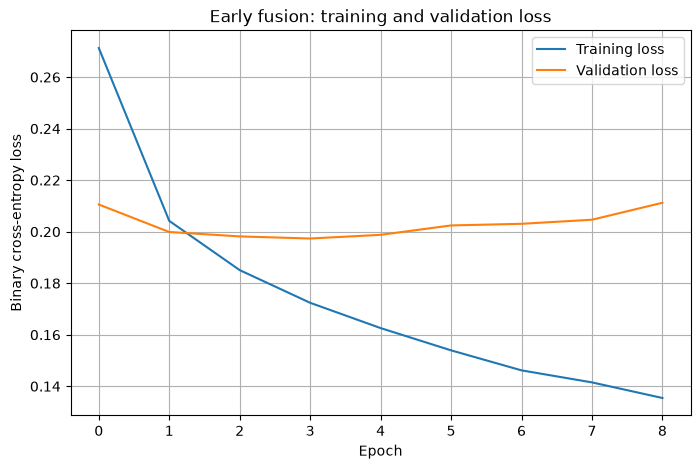

In [23]:


# Join each movie's text and poster features side by side
X_early_train = np.concatenate(
    [X_text_train_scaled, X_image_train_scaled], axis=1
).astype(np.float32)

X_early_val = np.concatenate(
    [X_text_val_scaled, X_image_val_scaled], axis=1
).astype(np.float32)

X_early_test = np.concatenate(
    [X_text_test_scaled, X_image_test_scaled], axis=1
).astype(np.float32)

print("Early-fusion shapes:")
print("Train:", X_early_train.shape)
print("Validation:", X_early_val.shape)
print("Test:", X_early_test.shape)

# Train the same type of model on the combined features
early_model = train_genre_mlp(
    X_early_train,
    X_early_val,
    y_train,
    y_val,
    model_name="Early fusion"
)

In [24]:



# Get predicted probabilities for the validation movies
early_model.eval()

with torch.no_grad():
    early_val_tensor = torch.tensor(
        X_early_val,
        dtype=torch.float32,
        device=device
    )
    early_val_probs = torch.sigmoid(early_model(early_val_tensor)).cpu().numpy()

# Convert probabilities to binary predictions using a 0.5 cutoff
y_val_true = np.asarray(y_val).astype(int)
early_val_preds = (early_val_probs >= 0.5).astype(int)

# Overall multi-label F1 scores
early_micro_f1 = f1_score(
    y_val_true, early_val_preds, average="micro", zero_division=0
)
early_macro_f1 = f1_score(
    y_val_true, early_val_preds, average="macro", zero_division=0
)

print(f"Early-fusion validation micro-F1 at 0.5 cutoff: {early_micro_f1:.4f}")
print(f"Early-fusion validation macro-F1 at 0.5 cutoff: {early_macro_f1:.4f}")

# Per-genre precision, recall, F1, and average precision
precision, recall, genre_f1, support = precision_recall_fscore_support(
    y_val_true,
    early_val_preds,
    average=None,
    zero_division=0
)

genre_ap = average_precision_score(
    y_val_true,
    early_val_probs,
    average=None
)

early_results = pd.DataFrame({
    "Genre": genre_names,
    "Precision": precision,
    "Recall": recall,
    "F1": genre_f1,
    "Average Precision": genre_ap,
    "Positive examples": support
})

print(f"Early-fusion mean per-genre AP: {genre_ap.mean():.4f}")
display(early_results.sort_values("Average Precision"))

Early-fusion validation micro-F1 at 0.5 cutoff: 0.5822
Early-fusion validation macro-F1 at 0.5 cutoff: 0.4345
Early-fusion mean per-genre AP: 0.5238


,Genre,Precision,Recall,F1,Average Precision,Positive examples
21,Short,0.000000,0.000000,0.000000,0.199711,48
18,Musical,0.272727,0.070588,0.112150,0.226432,85
22,Film-Noir,0.000000,0.000000,0.000000,0.287904,34
13,Biography,0.485714,0.118056,0.189944,0.301782,144
15,History,0.500000,0.093220,0.157143,0.308663,118
9,Mystery,0.518987,0.196172,0.284722,0.346639,209
11,Fantasy,0.567010,0.295699,0.388693,0.446729,186
6,Adventure,0.540698,0.334532,0.413333,0.451590,278
16,Music,0.644444,0.290000,0.400000,0.485961,100
2,Romance,0.550351,0.428832,0.482051,0.503452,548


In [25]:
# Average the separate models' predicted probabilities
late_val_probs = (text_val_probs + poster_val_probs) / 2

# Apply the same 0.5 cutoff used for the earlier comparisons
late_val_preds = (late_val_probs >= 0.5).astype(int)

late_micro_f1 = f1_score(
    y_val_true, late_val_preds, average="micro", zero_division=0
)
late_macro_f1 = f1_score(
    y_val_true, late_val_preds, average="macro", zero_division=0
)

# Calculate metrics for each genre
precision, recall, genre_f1, support = precision_recall_fscore_support(
    y_val_true,
    late_val_preds,
    average=None,
    zero_division=0
)

late_genre_ap = average_precision_score(
    y_val_true,
    late_val_probs,
    average=None
)

late_results = pd.DataFrame({
    "Genre": genre_names,
    "Precision": precision,
    "Recall": recall,
    "F1": genre_f1,
    "Average Precision": late_genre_ap,
    "Positive examples": support
})

print(f"Late-fusion validation micro-F1 at 0.5 cutoff: {late_micro_f1:.4f}")
print(f"Late-fusion validation macro-F1 at 0.5 cutoff: {late_macro_f1:.4f}")
print(f"Late-fusion mean per-genre AP: {late_genre_ap.mean():.4f}")

display(late_results.sort_values("Average Precision"))

Late-fusion validation micro-F1 at 0.5 cutoff: 0.5065
Late-fusion validation macro-F1 at 0.5 cutoff: 0.2825
Late-fusion mean per-genre AP: 0.5720


,Genre,Precision,Recall,F1,Average Precision,Positive examples
22,Film-Noir,0.000000,0.000000,0.000000,0.156314,34
21,Short,0.000000,0.000000,0.000000,0.212109,48
18,Musical,0.000000,0.000000,0.000000,0.262947,85
15,History,0.000000,0.000000,0.000000,0.406350,118
13,Biography,0.666667,0.013889,0.027211,0.414781,144
9,Mystery,0.000000,0.000000,0.000000,0.422466,209
6,Adventure,0.718750,0.165468,0.269006,0.498701,278
11,Fantasy,0.862069,0.134409,0.232558,0.511846,186
2,Romance,0.670213,0.229927,0.342391,0.539839,548
16,Music,1.000000,0.050000,0.095238,0.607466,100


In [26]:
threshold_grid = np.arange(0.05, 0.96, 0.05)
late_thresholds = np.full(len(genre_names), 0.5)

# Choose the cutoff that gives the best validation F1 for each genre
for j in range(len(genre_names)):
    best_f1 = -1

    for threshold in threshold_grid:
        predictions_for_genre = (
            late_val_probs[:, j] >= threshold
        ).astype(int)

        score = f1_score(
            y_val_true[:, j],
            predictions_for_genre,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            late_thresholds[j] = threshold

# Make predictions using each genre's selected cutoff
late_tuned_preds = (
    late_val_probs >= late_thresholds.reshape(1, -1)
).astype(int)

late_tuned_micro_f1 = f1_score(
    y_val_true, late_tuned_preds, average="micro", zero_division=0
)
late_tuned_macro_f1 = f1_score(
    y_val_true, late_tuned_preds, average="macro", zero_division=0
)

print(f"Late fusion tuned validation micro-F1: {late_tuned_micro_f1:.4f}")
print(f"Late fusion tuned validation macro-F1: {late_tuned_macro_f1:.4f}")

# Show the selected cutoff and resulting scores for each genre
precision, recall, genre_f1, support = precision_recall_fscore_support(
    y_val_true,
    late_tuned_preds,
    average=None,
    zero_division=0
)

late_tuned_results = pd.DataFrame({
    "Genre": genre_names,
    "Cutoff": late_thresholds,
    "Precision": precision,
    "Recall": recall,
    "F1": genre_f1,
    "Average Precision": late_genre_ap,
    "Positive examples": support
})

display(late_tuned_results.sort_values("F1"))

Late fusion tuned validation micro-F1: 0.6342
Late fusion tuned validation macro-F1: 0.5656


,Genre,Cutoff,Precision,Recall,F1,Average Precision,Positive examples
22,Film-Noir,0.10,0.171429,0.352941,0.230769,0.156314,34
21,Short,0.10,0.203125,0.270833,0.232143,0.212109,48
18,Musical,0.15,0.303030,0.352941,0.326087,0.262947,85
9,Mystery,0.20,0.482353,0.392344,0.432718,0.422466,209
15,History,0.15,0.432000,0.457627,0.444444,0.406350,118
13,Biography,0.15,0.389163,0.548611,0.455331,0.414781,144
11,Fantasy,0.20,0.418868,0.596774,0.492239,0.511846,186
6,Adventure,0.25,0.488818,0.550360,0.517766,0.498701,278
2,Romance,0.25,0.426230,0.759124,0.545932,0.539839,548
5,Action,0.25,0.544335,0.629630,0.583884,0.624090,351


## 8. Validation Comparison

The four approaches are compared on the validation set after threshold optimisation. The selected thresholds are stored for the final test evaluation.

The test set is not used during model training or threshold selection.

In [28]:
threshold_grid = np.arange(0.05, 0.96, 0.05)

validation_probs = {
    "Text-only": text_val_probs,
    "Poster-only": poster_val_probs,
    "Early fusion": early_val_probs,
    "Late fusion": late_val_probs
}

validation_comparison = []

for model_name, probs in validation_probs.items():
    thresholds = np.full(len(genre_names), 0.5)

    # Select the best validation F1 cutoff separately for each genre
    for j in range(len(genre_names)):
        best_f1 = -1

        for cutoff in threshold_grid:
            genre_predictions = (probs[:, j] >= cutoff).astype(int)
            score = f1_score(
                y_val_true[:, j],
                genre_predictions,
                zero_division=0
            )

            if score > best_f1:
                best_f1 = score
                thresholds[j] = cutoff

    tuned_predictions = (
        probs >= thresholds.reshape(1, -1)
    ).astype(int)

    validation_comparison.append({
        "Model": model_name,
        "Tuned micro-F1": f1_score(
            y_val_true, tuned_predictions,
            average="micro", zero_division=0
        ),
        "Tuned macro-F1": f1_score(
            y_val_true, tuned_predictions,
            average="macro", zero_division=0
        ),
        "Mean per-genre AP": average_precision_score(
            y_val_true, probs, average="macro"
        )
    })

    # Keep the cutoffs for the final test evaluation
    if model_name == "Text-only":
        text_thresholds = thresholds
    elif model_name == "Poster-only":
        poster_thresholds = thresholds
    elif model_name == "Early fusion":
        early_thresholds = thresholds
    elif model_name == "Late fusion":
        late_thresholds = thresholds

validation_comparison = pd.DataFrame(validation_comparison)
display(validation_comparison.sort_values("Tuned macro-F1", ascending=False))

,Model,Tuned micro-F1,Tuned macro-F1,Mean per-genre AP
3,Late fusion,0.634220,0.565606,0.571985
0,Text-only,0.616883,0.544146,0.540993
2,Early fusion,0.606310,0.531360,0.523783
1,Poster-only,0.430533,0.342168,0.298518


## 9. Final Test Evaluation

The trained models are now evaluated once on the held-out test set. Each model uses the genre-specific thresholds selected from the validation data.

Late fusion is produced by averaging the text-only and poster-only predicted probabilities.

In [30]:
def predict_probabilities(model, X_array):
    model.eval()

    with torch.no_grad():
        X_tensor = torch.tensor(
            X_array,
            dtype=torch.float32,
            device=device
        )
        probabilities = torch.sigmoid(model(X_tensor)).cpu().numpy()

    return probabilities


# Predict on the held-out test set
text_test_probs = predict_probabilities(
    text_model, X_text_test_scaled
)
poster_test_probs = predict_probabilities(
    poster_model, X_image_test_scaled
)
early_test_probs = predict_probabilities(
    early_model, X_early_test
)

# Late fusion averages the text and poster probabilities
late_test_probs = (text_test_probs + poster_test_probs) / 2

test_probs_by_model = {
    "Text-only": text_test_probs,
    "Poster-only": poster_test_probs,
    "Early fusion": early_test_probs,
    "Late fusion": late_test_probs
}

test_thresholds_by_model = {
    "Text-only": text_thresholds,
    "Poster-only": poster_thresholds,
    "Early fusion": early_thresholds,
    "Late fusion": late_thresholds
}

y_test_true = np.asarray(y_test).astype(int)

# Evaluate each approach using its validation-selected cutoffs
test_comparison = []

for model_name, probabilities in test_probs_by_model.items():
    cutoffs = test_thresholds_by_model[model_name]
    predictions = (probabilities >= cutoffs.reshape(1, -1)).astype(int)

    test_comparison.append({
        "Model": model_name,
        "Test micro-F1": f1_score(
            y_test_true, predictions,
            average="micro", zero_division=0
        ),
        "Test macro-F1": f1_score(
            y_test_true, predictions,
            average="macro", zero_division=0
        ),
        "Test mean per-genre AP": average_precision_score(
            y_test_true, probabilities, average="macro"
        )
    })

test_comparison = pd.DataFrame(test_comparison)
display(test_comparison.sort_values("Test macro-F1", ascending=False))

,Model,Test micro-F1,Test macro-F1,Test mean per-genre AP
3,Late fusion,0.627388,0.556740,0.570677
0,Text-only,0.614860,0.536290,0.543443
2,Early fusion,0.595778,0.507151,0.515367
1,Poster-only,0.424031,0.332640,0.297164


## 10. Per-Genre and Error Analysis

The best-performing late-fusion model is examined in more detail. Precision, recall, F1 and average precision are calculated separately for every genre.

Exact-match accuracy and Hamming loss are also calculated to show performance at the complete-movie and individual-label levels.

In [32]:
# Apply the cutoffs chosen on the validation set
late_test_preds = (
    late_test_probs >= late_thresholds.reshape(1, -1)
).astype(int)

# Calculate test metrics for each genre
precision, recall, genre_f1, support = precision_recall_fscore_support(
    y_test_true,
    late_test_preds,
    average=None,
    zero_division=0
)

late_test_ap = average_precision_score(
    y_test_true,
    late_test_probs,
    average=None
)

late_test_genre_results = pd.DataFrame({
    "Genre": genre_names,
    "Cutoff": late_thresholds,
    "Precision": precision,
    "Recall": recall,
    "F1": genre_f1,
    "Average Precision": late_test_ap,
    "Positive examples": support
})

display(
    late_test_genre_results.sort_values(
        "Average Precision",
        ascending=False
    )
)

,Genre,Cutoff,Precision,Recall,F1,Average Precision,Positive examples
0,Drama,0.50,0.720439,0.823757,0.768642,0.827464,4142
8,Documentary,0.25,0.747253,0.756757,0.751975,0.797242,629
1,Comedy,0.45,0.725334,0.664496,0.693584,0.769942,2611
7,Horror,0.30,0.670616,0.686061,0.678250,0.745761,825
19,Western,0.20,0.713542,0.652381,0.681592,0.730866,210
10,Sci-Fi,0.30,0.771765,0.559727,0.648863,0.718860,586
14,War,0.20,0.596112,0.688279,0.638889,0.692039,401
20,Sport,0.20,0.756410,0.617801,0.680115,0.686208,191
17,Animation,0.25,0.606154,0.643791,0.624406,0.678480,306
4,Crime,0.25,0.592537,0.682717,0.634439,0.651408,1163


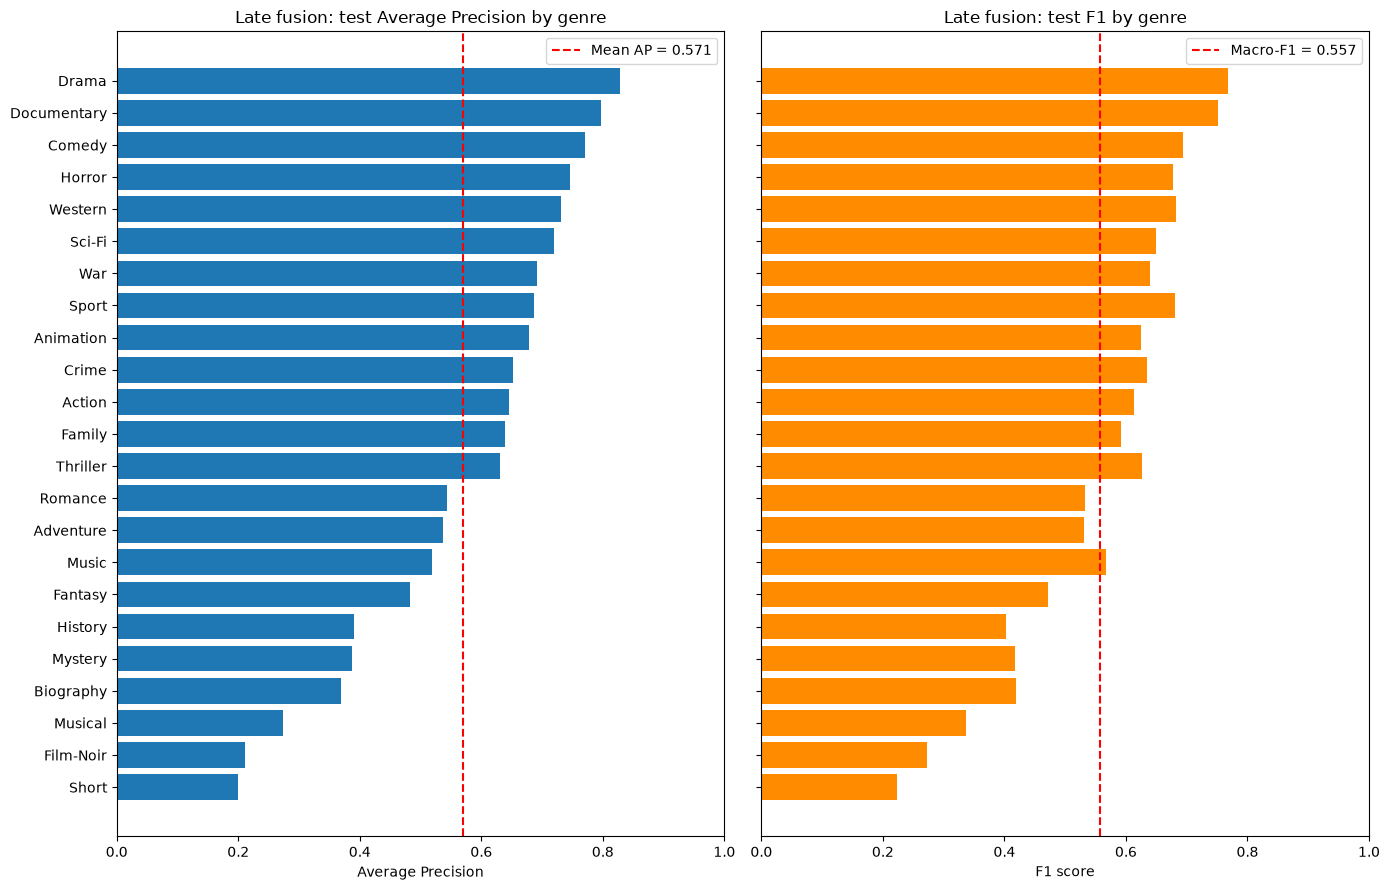

In [33]:


plot_data = late_test_genre_results.sort_values(
    "Average Precision",
    ascending=True
)

fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharey=True)

# Average Precision by genre
axes[0].barh(plot_data["Genre"], plot_data["Average Precision"])
axes[0].axvline(
    late_test_ap.mean(),
    color="red",
    linestyle="--",
    label=f"Mean AP = {late_test_ap.mean():.3f}"
)
axes[0].set_title("Late fusion: test Average Precision by genre")
axes[0].set_xlabel("Average Precision")
axes[0].set_xlim(0, 1)
axes[0].legend()

# F1 by genre
axes[1].barh(plot_data["Genre"], plot_data["F1"], color="darkorange")
axes[1].axvline(
    plot_data["F1"].mean(),
    color="red",
    linestyle="--",
    label=f"Macro-F1 = {plot_data['F1'].mean():.3f}"
)
axes[1].set_title("Late fusion: test F1 by genre")
axes[1].set_xlabel("F1 score")
axes[1].set_xlim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()

In [34]:


exact_match = accuracy_score(y_test_true, late_test_preds)
wrong_label_fraction = hamming_loss(y_test_true, late_test_preds)

print(f"Movies with every genre prediction correct: {exact_match:.1%}")
print(f"Individual movie-genre decisions wrong: {wrong_label_fraction:.1%}")

Movies with every genre prediction correct: 13.4%
Individual movie-genre decisions wrong: 8.7%


In [35]:


all_negative_preds = np.zeros_like(y_test_true)

print(
    f"Model Hamming loss: "
    f"{hamming_loss(y_test_true, late_test_preds):.1%}"
)
print(
    f"All-negative baseline Hamming loss: "
    f"{hamming_loss(y_test_true, all_negative_preds):.1%}"
)
print(
    f"Average true genres per movie: "
    f"{y_test_true.sum(axis=1).mean():.2f}"
)
print(
    f"Average predicted genres per movie: "
    f"{late_test_preds.sum(axis=1).mean():.2f}"
)
print(
    f"Micro precision: "
    f"{precision_score(y_test_true, late_test_preds, average='micro', zero_division=0):.1%}"
)
print(
    f"Micro recall: "
    f"{recall_score(y_test_true, late_test_preds, average='micro', zero_division=0):.1%}"
)

Model Hamming loss: 8.7%
All-negative baseline Hamming loss: 10.8%
Average true genres per movie: 2.48
Average predicted genres per movie: 2.87
Micro precision: 58.6%
Micro recall: 67.6%


## 11. Conclusion

Late fusion achieved the strongest overall test performance:

- Micro-F1: 0.6274
- Macro-F1: 0.5567
- Mean per-genre average precision: 0.5707
- Exact-match accuracy: 13.4%
- Hamming loss: 8.7%

Text-only was the strongest unimodal model, while poster-only produced the weakest results. Early fusion did not outperform text-only. This indicates that poster information provided modest complementary value when the predictions were combined through late fusion.